# Visualization Exercise Sheet

----------------------------------------------------------

In these short questions we will have you work with data from the GALAH spectroscopic survey (https://www.galah-survey.org) of stars in the Milky Way disk, and practice some visualization techniques to help analyze trends in the data.

You will find helpful documentation and examples to help you make the plots at the following graph galleries.
https://python-graph-gallery.com

https://matplotlib.org/stable/plot_types/index.html

**Download the data file 'galahamr.sav' located in the Moodle exercises page, which contains measurements of physical properties of ~7000 nearby stars.**

In [177]:
import numpy as np
from matplotlib import pyplot as plt

In [178]:
#Read in data set
from scipy.io import readsav
filepath = '/Users/alexandercao/AstroProgramming/NUM/exercise2/galahamr.sav'  #change this to the path on your computer where the file is stored
stars = readsav(filepath)  

In [179]:
#Pull out some attributes of the stars we want to look at and store them in arrays
logg = stars['f']['logg']  #surface gravity   
teff = stars['f']['teff']  #effective temperature
mass = stars['f']['massmean']  #mass
lum = mass**4.  #luminosity for stars 0.43 < Msun < 2
age = stars['f']['agemean'] #age
feh = stars['f']['__fe_h_'] #[Fe/H], a logarithmic Iron abundance
afe = stars['f']['__alpha_fe_']  #[Alpha/Fe], logarithmic relative abundance of alpha elements(O, Si, etc.) relative to Iron

### 1) Consider one version of the Hertzsprung-Russell diagram using effective temperature and surface gravity of the stars ( $T_{eff}$, log(g) ).  Make two types of plots of the stars, with clearly labeled axes and colorbars where suitable: 
* a) a scatter plot with the points colored by age 
* b) a 2D density plot using, e.g. the **kde** package along with the **pcolormesh** routine in matplotlib; or hist2d within matplotlib

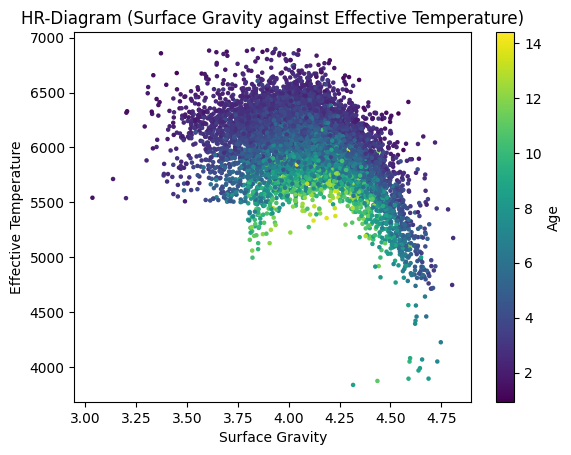

In [180]:
# Convert the data into NumPy arrays
x = np.array(logg)  # Surface gravity values
y = np.array(teff)  # Effective temperature values
z = np.array(age)   # Age values

# Create a scatter plot
# x-axis: Surface gravity
# y-axis: Effective temperature
# Color: Age
scatter = plt.scatter(x, y, c=z, cmap='viridis', s=5)
plt.colorbar(scatter, label='Age')
plt.title("HR-Diagram (Surface Gravity against Effective Temperature)")
plt.xlabel("Surface Gravity")
plt.ylabel("Effective Temperature")
plt.show()


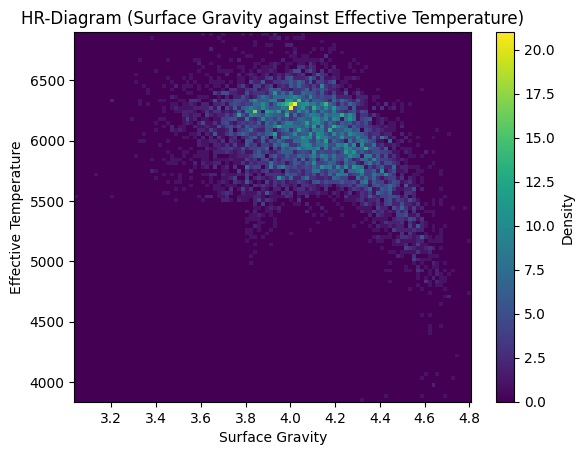

In [181]:
# Create a 2D histogram to show the density of data points
# x represents surface gravity
# y represents effective temperature
# bins=100 divides the plot into 100 bins along each axis
plt.hist2d(x, y, bins=100)
plt.colorbar(label="Density")
plt.title("HR-Diagram (Surface Gravity against Effective Temperature)")
plt.xlabel("Surface Gravity")
plt.ylabel("Effective Temperature")
plt.show()


### 2) Use a built-in, or hand-written routine to compute the running average of $T_{eff}$ as a function of $log(g)$.  Overplot this average approximation to the distribution of stars.  It should roughly subdivide the sample into cooler and hotter stars at a given value of $log(g)$.

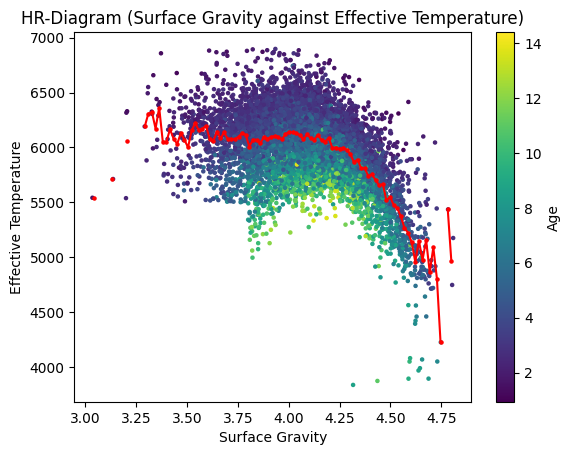

In [182]:
from scipy.stats import binned_statistic

# Calculate the mean effective temperature (y) for each bin of surface gravity (x)
# bins=100 divides the surface gravity data into 100 bins
mean_teff, bin_edges, bin_number = binned_statistic(x, y, statistic='mean', bins=100)

# Calculate the center of each bin using its edges
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Create a scatter plot of surface gravity against effective temperature
# The color of each point represents its age (z)
# cmap='viridis' sets the color scheme and s=5 sets the point size
scatter = plt.scatter(x, y, c=z, cmap='viridis', s=5)
plt.colorbar(scatter, label='Age')
plt.title("HR-Diagram (Surface Gravity against Effective Temperature)")
plt.xlabel("Surface Gravity")
plt.ylabel("Effective Temperature")

# Plot the mean effective temperature for each bin
plt.scatter(bin_centers, mean_teff, s=5, c='red')
plt.plot(bin_centers, mean_teff, c='red')
plt.show()


### 3) [OPTIONAL]  Compute the mean and standard deviation ($\sigma$) of the ages of the cool and hot star sub-samples

* What percent of stars have an age that is within $1-\sigma$ of the mean ages of *both* the cool and hot star sub-samples?  e.g., the fraction of stars that have ages within
 
$(mean(age_{hot}) +\sigma(age_{hot}))$ $\leq age \leq$ $(mean(age_{cool}) -\sigma(age_{cool}))$

In [183]:
# Get the lower and upper edges of each surface-gravity bin
lower_edges = bin_edges[:-1]
upper_edges = bin_edges[1:]

# Create empty lists to store the ages of hot and cool stars
ages_hot = []
ages_cool = []

# Loop through each bin of surface gravity
for m, i in enumerate(lower_edges):

    # Loop through each star's surface-gravity value
    for n, j in enumerate(x):

        # Check whether the star falls within the current bin
        if (lower_edges[m] <= j < upper_edges[m]):

            # Compare the star's effective temperature with the mean
            # effective temperature of its bin
            if (y[n] > mean_teff[m]):

                # If its temperature is above the bin mean,
                # classify it as a hot star and store its age
                ages_hot.append(z[n])

            else:
                # Otherwise, classify it as a cool star
                # and store its age
                ages_cool.append(z[n])

        else:
            # Skip stars that do not belong to this bin
            continue

# Calculate the mean and standard deviation of cool and hot stars
ages_hot_mean = np.mean(ages_hot)
ages_hot_std = np.std(ages_hot)
ages_cool_mean = np.mean(ages_cool)
ages_cool_std = np.std(ages_cool)

# Create an empty list to store ages that fall within
# one standard deviation of BOTH group means
ages_within = []

# Check the age of every star in the dataset
for age in z:

    # Check whether the age falls within one standard deviation
    # of the hot-star mean AND the cool-star mean
    if (
        (ages_hot_mean - ages_hot_std <= age <= ages_hot_mean + ages_hot_std)
        and
        (ages_cool_mean - ages_cool_std <= age <= ages_cool_mean + ages_cool_std)
    ):

        # If both conditions are satisfied, store the age
        ages_within.append(age)

    else:
        # Skip ages that do not satisfy both conditions
        continue

# Calculate the fraction of all stars whose ages satisfy both conditions
percentage = len(ages_within) / len(z)

print(f"Hot Stars: Mean = {ages_hot_mean:.2f} Gyr, Std = {ages_hot_std:.2f} Gyr")
print(f"Cool Stars: Mean = {ages_cool_mean:.2f} Gyr, Std = {ages_cool_std:.2f} Gyr")
print(f"Percentage of stars within 1 sigma: {percentage * 100:.2f}%")


Hot Stars: Mean = 3.65 Gyr, Std = 1.16 Gyr
Cool Stars: Mean = 6.77 Gyr, Std = 2.32 Gyr
Percentage of stars within 1 sigma: 5.82%


### 4) Create two versions of a *weighted* 2D density distribution of the sample of stars in the plane of **[Fe/H]** as a function of **age**:
* a) One where the density distribution is weighted by the mass of the stars
* b) One where the density distribution is weighted by the luminosity of the stars

Compute the weighted average metallicity and age for both cases and indicate them on the density distributions.

Mass weighted averages: Metallicity: -0.05, Age: 4.89 Gyr
Luminosity weighted averages: Metallicity: -0.03, Age: 4.15 Gyr


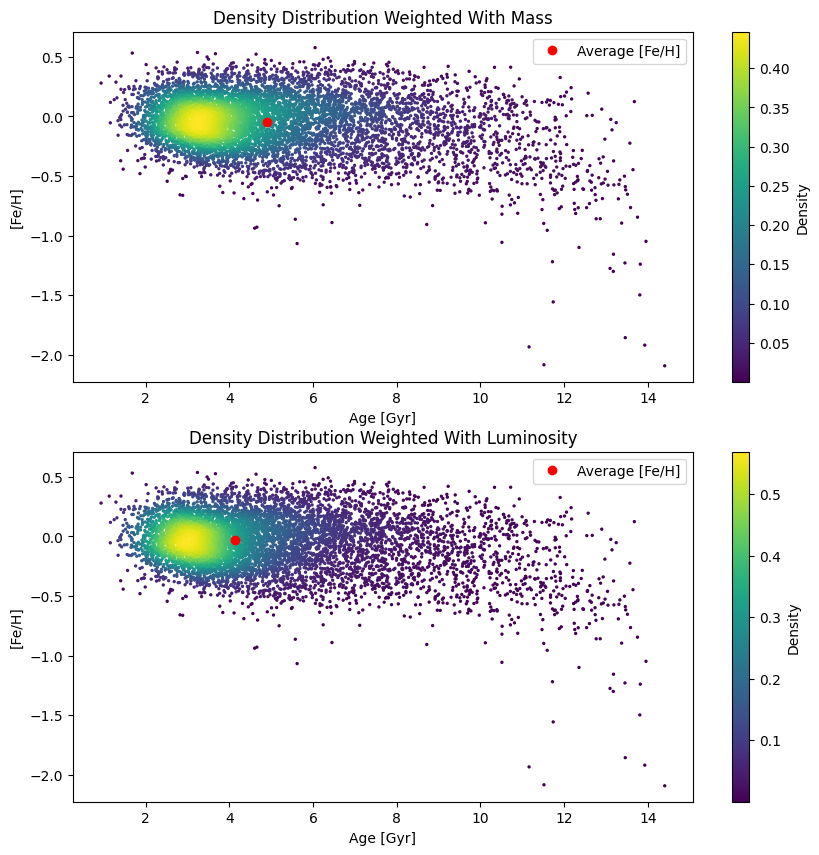

In [184]:
from scipy.stats import gaussian_kde

metallicity = np.array(feh)
ages = z

mass_weight = np.array(mass)
lum_weight = np.array(lum)

# Calculate the 2D kernel density estimation (KDE) weighted by stellar mass
# This estimates the density distribution of stars in age-metallicity space
kde_mass = gaussian_kde(np.vstack([ages, metallicity]),weights=mass_weight)

# Calculate the 2D KDE weighted by stellar luminosity
# Brighter stars contribute more strongly to the weighted density estimate
kde_lum = gaussian_kde(np.vstack([ages, metallicity]),weights=lum_weight)

# Calculate the mass-weighted average age and metallicity
# Stars with greater mass contribute more to the averages
age_avg_mass = np.average(ages, weights=mass_weight)
feh_avg_mass = np.average(metallicity, weights=mass_weight)

# Calculate the luminosity-weighted average age and metallicity
# Stars with greater luminosity contribute more to the averages
age_avg_lum = np.average(ages, weights=lum_weight)
feh_avg_lum = np.average(metallicity, weights=lum_weight)

print(f"Mass weighted averages: Metallicity: {feh_avg_mass:.2f}, Age: {age_avg_mass:.2f} Gyr")
print(f"Luminosity weighted averages: Metallicity: {feh_avg_lum:.2f}, Age: {age_avg_lum:.2f} Gyr")

# Create a figure with two vertically arranged subplots
# figsize=(10, 10) sets the overall figure size
fig, ax = plt.subplots(2, 1, figsize=(10, 10))

# Evaluate the mass-weighted KDE at each star's age and metallicity
# Use the estimated density values to color the scatter plot
sc0 = ax[0].scatter(
    ages,
    metallicity,
    c=kde_mass(np.vstack([ages, metallicity])),
    s=2,
    cmap="viridis"
)

# Mark the mass-weighted average age and metallicity with a red circle
ax[0].plot(
    age_avg_mass,
    feh_avg_mass,
    'ro',
    label="Average [Fe/H]"
)

# Add a title and axis labels to the first subplot
ax[0].set_title("Density Distribution Weighted With Mass")
ax[0].set_xlabel("Age [Gyr]")
ax[0].set_ylabel("[Fe/H]")
ax[0].legend()
fig.colorbar(sc0, ax=ax[0], label="Density")

# Evaluate the luminosity-weighted KDE at each star's age and metallicity
# Use the estimated density values to color the scatter plot
sc1 = ax[1].scatter(
    ages,
    metallicity,
    c=kde_lum(np.vstack([ages, metallicity])),
    s=2,
    cmap="viridis"
)

# Mark the luminosity-weighted average age and metallicity with a red circle
ax[1].plot(
    age_avg_lum,
    feh_avg_lum,
    'ro',
    label="Average [Fe/H]"
)

ax[1].set_title("Density Distribution Weighted With Luminosity")
ax[1].set_xlabel("Age [Gyr]")
ax[1].set_ylabel("[Fe/H]")
ax[1].legend()
fig.colorbar(sc1, ax=ax[1], label="Density")
plt.show()
